In [ ]:
# Install XGBoost automatically if missing
!pip install -q xgboost

from google.colab import files
import os

# Prompt to upload the dataset file if not present
if not os.path.exists('electricity_consumption_optimization_dataset (1).csv'):
    print("Please upload 'electricity_consumption_optimization_dataset (1).csv':")
    uploaded = files.upload()

Please upload 'electricity_consumption_optimization_dataset (1).csv':


Saving electricity_consumption_optimization_dataset (1).csv to electricity_consumption_optimization_dataset (1).csv


In [ ]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, IsolationForest
import xgboost as xgb

df = pd.read_csv('/content/electricity_consumption_optimization_dataset.csv')

df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['Month'] = df['Timestamp'].dt.month
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

df_ml = df.drop(columns=['Timestamp'])

target_col = 'Energy Consumption (kWh)'
X = df_ml.drop(columns=[target_col, 'Carbon Emission Reduction Category', 'Peak Demand Reduction Indicator'])
y = df_ml[target_col]

categorical_cols = ['Building Type', 'Occupancy Schedule', 'Building Orientation']
numeric_cols = [c for c in X.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

X_train_prep = preprocessor.fit_transform(X_train)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_prep, y_train)

xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6, random_state=42)
xgb_model.fit(X_train_prep, y_train)

iso_forest = IsolationForest(contamination=0.02, random_state=42)
iso_forest.fit(X_train_prep)

joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(rf_model, 'rf_model.pkl')
joblib.dump(xgb_model, 'xgb_model.pkl')
joblib.dump(iso_forest, 'iso_forest.pkl')

X_test.to_csv('X_test.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print("Training completed and artifacts saved successfully!")

Training completed and artifacts saved successfully!


Random Forest Regressor -> RMSE: 20.4294, MAE: 16.2393, R2: -0.0121
XGBoost Regressor -> RMSE: 20.3803, MAE: 16.2141, R2: -0.0073
Anomalies detected in test set: 239


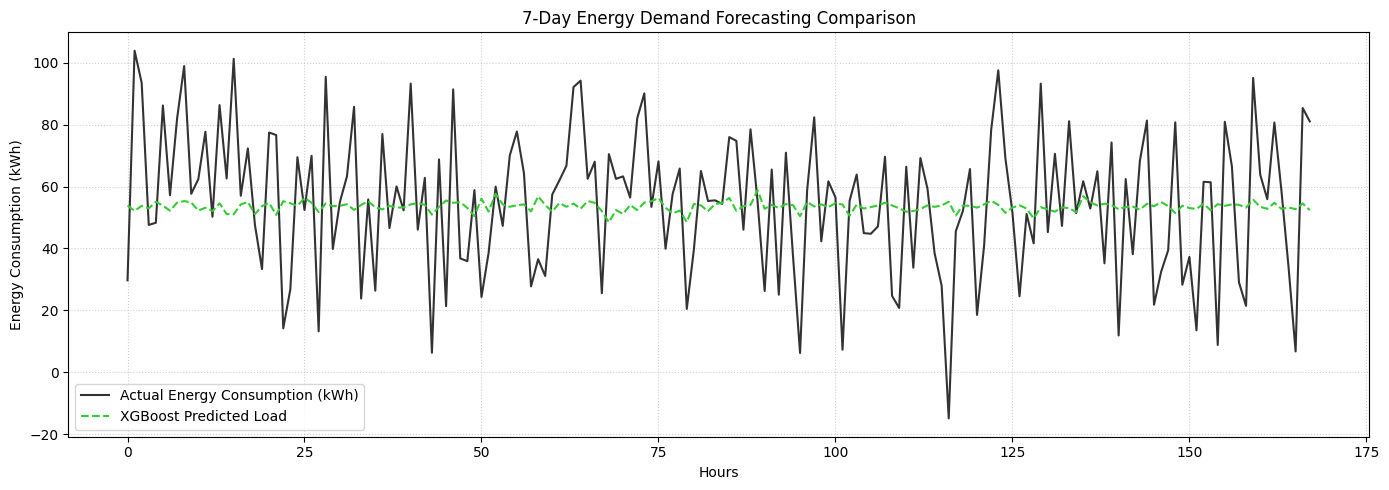

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

preprocessor = joblib.load('preprocessor.pkl')
rf_model = joblib.load('rf_model.pkl')
xgb_model = joblib.load('xgb_model.pkl')
iso_forest = joblib.load('iso_forest.pkl')

X_test = pd.read_csv('X_test.csv')
y_test = pd.read_csv('y_test.csv').squeeze("columns")

X_test_prep = preprocessor.transform(X_test)

rf_preds = rf_model.predict(X_test_prep)
xgb_preds = xgb_model.predict(X_test_prep)
anomalies = iso_forest.predict(X_test_prep)

def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name} -> RMSE: {rmse:.4f}, MAE: {mae:.4f}, R2: {r2:.4f}")

evaluate_model("Random Forest Regressor", y_test, rf_preds)
evaluate_model("XGBoost Regressor", y_test, xgb_preds)

print(f"Anomalies detected in test set: {(anomalies == -1).sum()}")

plt.figure(figsize=(14, 5))
plt.plot(y_test.values[:168], label='Actual Energy Consumption (kWh)', color='black', alpha=0.8)
plt.plot(xgb_preds[:168], label='XGBoost Predicted Load', color='limegreen', linestyle='--')
plt.title("7-Day Energy Demand Forecasting Comparison")
plt.xlabel("Hours")
plt.ylabel("Energy Consumption (kWh)")
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

=== Pipeline Complete ===
Random Forest -> RMSE: 20.43, MAE: 16.24, R2: -0.0121
XGBoost       -> RMSE: 20.38, MAE: 16.21, R2: -0.0073
Anomalies detected: 239



/tmp/ipykernel_2335/2475210967.py:84: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df['RMSE'], ax=axes[0], palette=['#2b5c8f', '#27ae60'])
/tmp/ipykernel_2335/2475210967.py:88: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df['MAE'], ax=axes[1], palette=['#2b5c8f', '#27ae60'])
/tmp/ipykernel_2335/2475210967.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics_df.index, y=metrics_df['R2'], ax=axes[2], palette=['#2b5c8f', '#27ae60'])


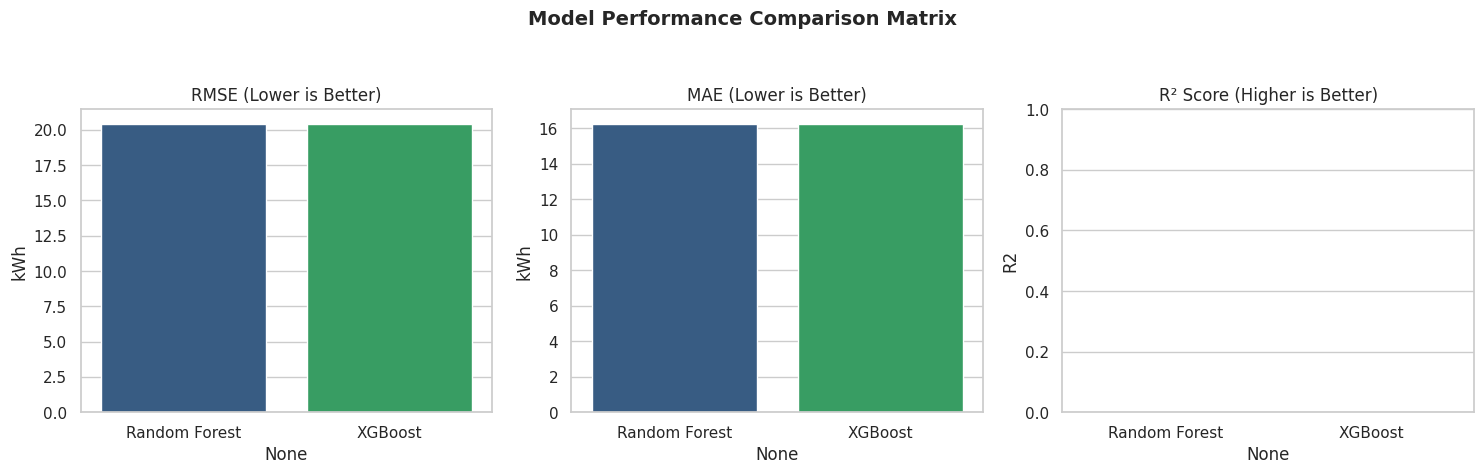

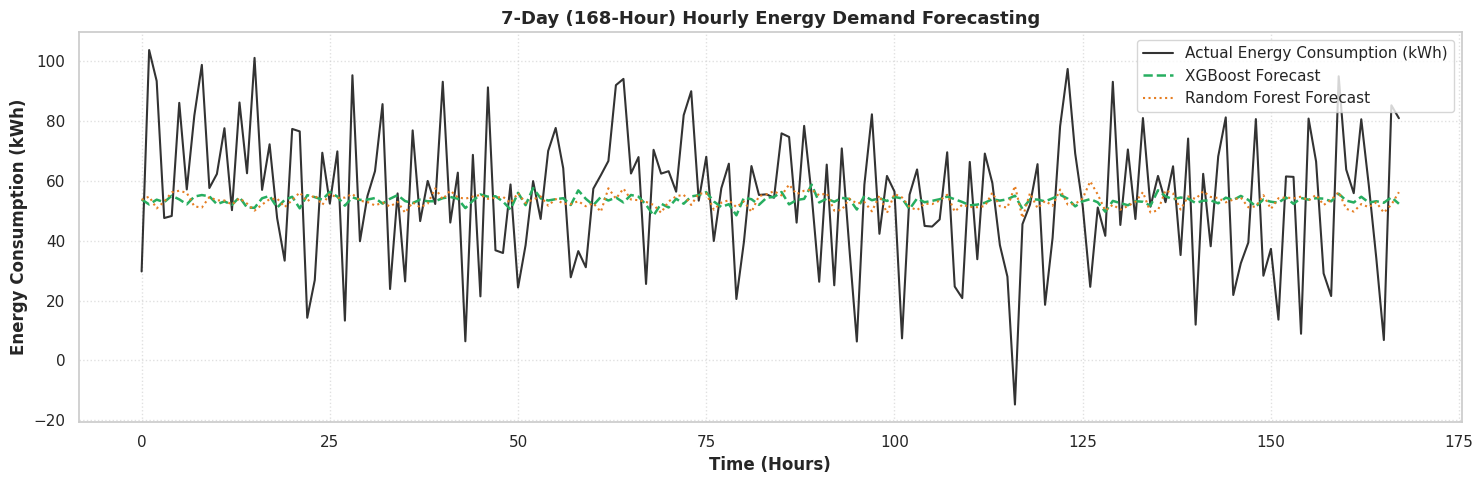

/tmp/ipykernel_2335/2475210967.py:122: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')


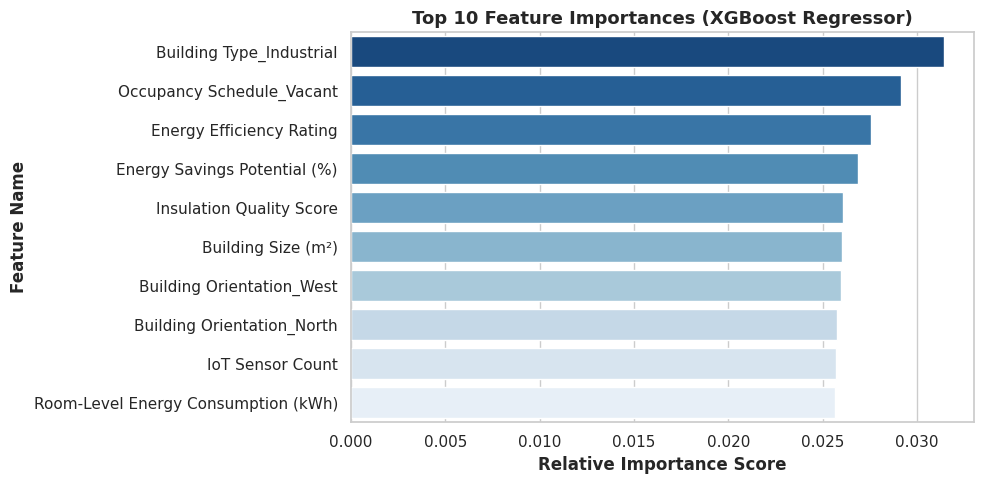

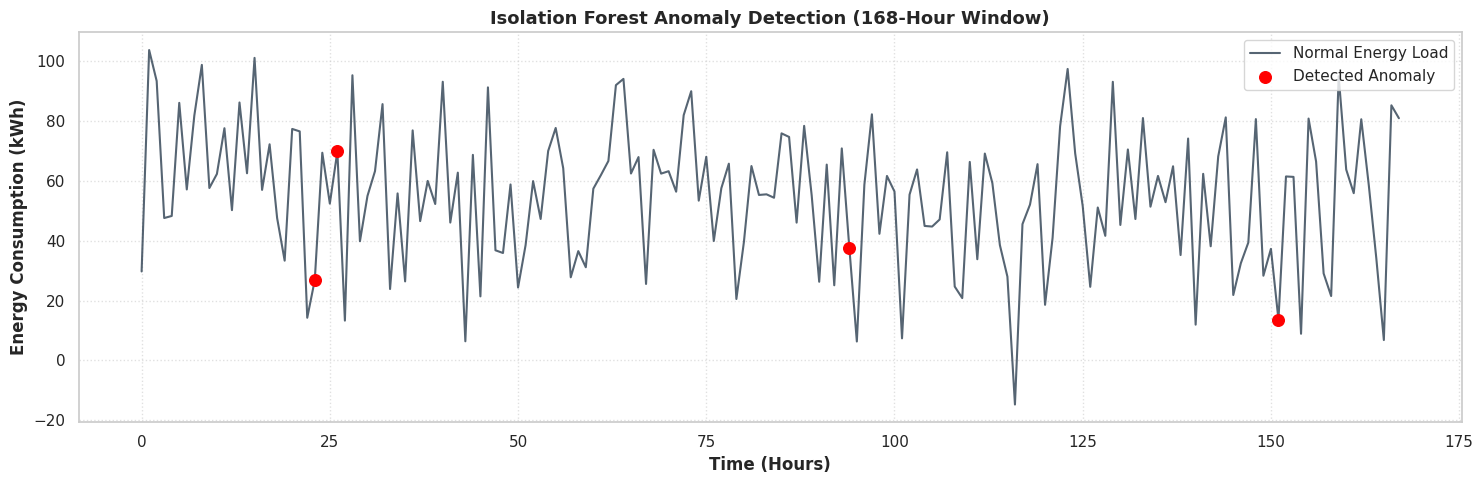

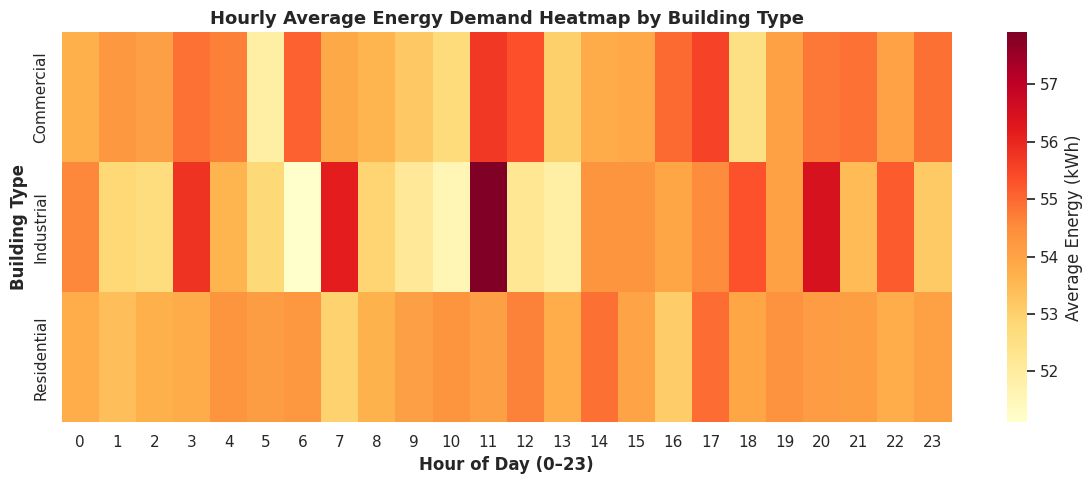

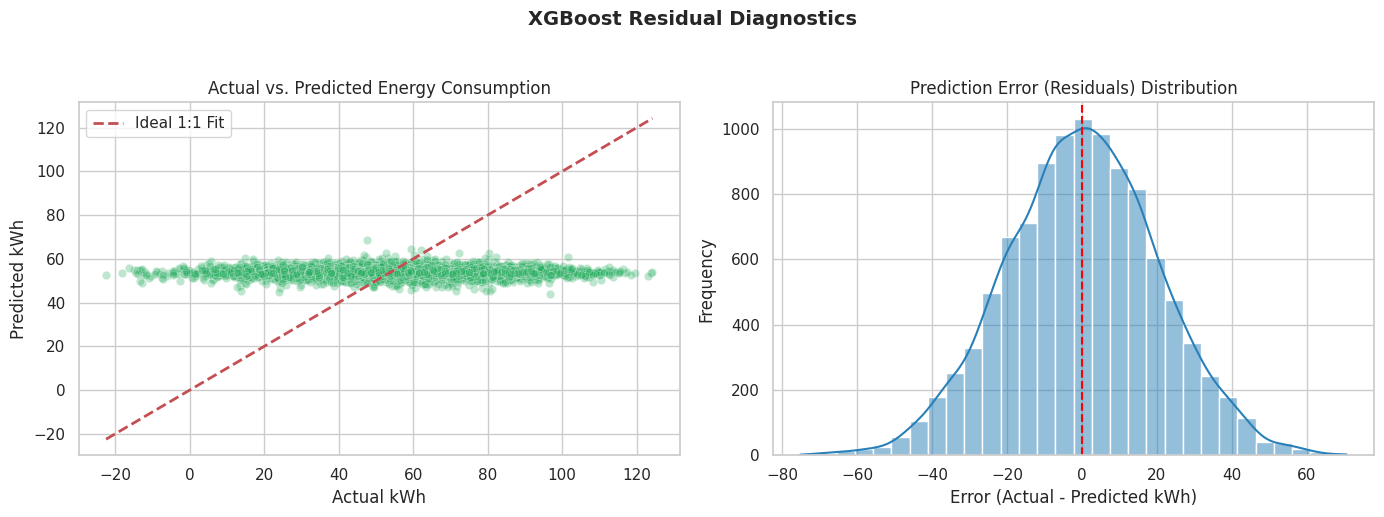

In [ ]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

sns.set_theme(style="whitegrid")

file_path = 'electricity_consumption_optimization_dataset (1).csv'
if not os.path.exists(file_path):
    print("Please upload your dataset file:")
    uploaded = files.upload()

df = pd.read_csv(file_path)

df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek
df['DayName'] = df['Timestamp'].dt.day_name()
df['Month'] = df['Timestamp'].dt.month
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

df_ml = df.drop(columns=['Timestamp', 'DayName'])

target_col = 'Energy Consumption (kWh)'
X = df_ml.drop(columns=[target_col, 'Carbon Emission Reduction Category', 'Peak Demand Reduction Indicator'])
y = df_ml[target_col]

categorical_cols = ['Building Type', 'Occupancy Schedule', 'Building Orientation']
numeric_cols = [c for c in X.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), categorical_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_prep, y_train)

xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6, random_state=42)
xgb_model.fit(X_train_prep, y_train)

iso_forest = IsolationForest(contamination=0.02, random_state=42)
iso_forest.fit(X_train_prep)

rf_preds = rf_model.predict(X_test_prep)
xgb_preds = xgb_model.predict(X_test_prep)
anomalies = iso_forest.predict(X_test_prep)

def get_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

rf_metrics = get_metrics(y_test, rf_preds)
xgb_metrics = get_metrics(y_test, xgb_preds)

print("=== Pipeline Complete ===")
print(f"Random Forest -> RMSE: {rf_metrics['RMSE']:.2f}, MAE: {rf_metrics['MAE']:.2f}, R2: {rf_metrics['R2']:.4f}")
print(f"XGBoost       -> RMSE: {xgb_metrics['RMSE']:.2f}, MAE: {xgb_metrics['MAE']:.2f}, R2: {xgb_metrics['R2']:.4f}")
print(f"Anomalies detected: {(anomalies == -1).sum()}\n")

metrics_df = pd.DataFrame([rf_metrics, xgb_metrics], index=['Random Forest', 'XGBoost'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.barplot(x=metrics_df.index, y=metrics_df['RMSE'], ax=axes[0], palette=['#2b5c8f', '#27ae60'])
axes[0].set_title("RMSE (Lower is Better)")
axes[0].set_ylabel("kWh")

sns.barplot(x=metrics_df.index, y=metrics_df['MAE'], ax=axes[1], palette=['#2b5c8f', '#27ae60'])
axes[1].set_title("MAE (Lower is Better)")
axes[1].set_ylabel("kWh")

sns.barplot(x=metrics_df.index, y=metrics_df['R2'], ax=axes[2], palette=['#2b5c8f', '#27ae60'])
axes[2].set_title("R² Score (Higher is Better)")
axes[2].set_ylim(0, 1.0)

plt.suptitle("Model Performance Comparison Matrix", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(y_test.values[:168], label='Actual Energy Consumption (kWh)', color='black', alpha=0.8, linewidth=1.5)
plt.plot(xgb_preds[:168], label='XGBoost Forecast', color='#27ae60', linestyle='--', linewidth=1.8)
plt.plot(rf_preds[:168], label='Random Forest Forecast', color='#e67e22', linestyle=':', linewidth=1.5)

plt.title("7-Day (168-Hour) Hourly Energy Demand Forecasting", fontsize=13, fontweight='bold')
plt.xlabel("Time (Hours)", fontweight='bold')
plt.ylabel("Energy Consumption (kWh)", fontweight='bold')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(ohe_feature_names)

importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='Blues_r')
plt.title("Top 10 Feature Importances (XGBoost Regressor)", fontsize=13, fontweight='bold')
plt.xlabel("Relative Importance Score", fontweight='bold')
plt.ylabel("Feature Name", fontweight='bold')
plt.tight_layout()
plt.show()

test_sample = X_test.iloc[:168].copy()
test_sample['Actual_kWh'] = y_test.values[:168]
test_sample['Anomaly'] = anomalies[:168]

plt.figure(figsize=(15, 5))
plt.plot(range(168), test_sample['Actual_kWh'], label='Normal Energy Load', color='#2c3e50', alpha=0.8)

anomaly_indices = np.where(test_sample['Anomaly'] == -1)[0]
plt.scatter(anomaly_indices, test_sample['Actual_kWh'].iloc[anomaly_indices],
            color='red', label='Detected Anomaly', s=70, zorder=5, marker='o')

plt.title("Isolation Forest Anomaly Detection (168-Hour Window)", fontsize=13, fontweight='bold')
plt.xlabel("Time (Hours)", fontweight='bold')
plt.ylabel("Energy Consumption (kWh)", fontweight='bold')
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

heatmap_data = df.groupby(['Building Type', 'Hour'])['Energy Consumption (kWh)'].mean().unstack()

plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=False, cbar_kws={'label': 'Average Energy (kWh)'})
plt.title("Hourly Average Energy Demand Heatmap by Building Type", fontsize=13, fontweight='bold')
plt.xlabel("Hour of Day (0–23)", fontweight='bold')
plt.ylabel("Building Type", fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_test, y=xgb_preds, ax=axes[0], alpha=0.3, color='#27ae60')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal 1:1 Fit')
axes[0].set_title("Actual vs. Predicted Energy Consumption")
axes[0].set_xlabel("Actual kWh")
axes[0].set_ylabel("Predicted kWh")
axes[0].legend()

residuals = y_test - xgb_preds
sns.histplot(residuals, kde=True, ax=axes[1], color='#2980b9', bins=30)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title("Prediction Error (Residuals) Distribution")
axes[1].set_xlabel("Error (Actual - Predicted kWh)")
axes[1].set_ylabel("Frequency")

plt.suptitle("XGBoost Residual Diagnostics", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()